# 03 - Dataloaders and trainer check (Stage 3, Step 2)
**Owner:** Maheen | **Receives from:** Aiman (processed shards + `manifest.csv`) | **Hands off to:** Amna (baseline training)

What this notebook checks:
1. The processed data loads from the shared Drive, using the frozen `split` column (never re-split)
2. The dataloaders give correct batches: shape, labels, train-only augmentation (shown as a picture)
3. The metrics module gives the right numbers on a known example
4. **Smoke test:** EfficientNet-B4 trains for 2 epochs on a small subset with no errors, checkpoints are saved to Drive
5. **Resume test:** training continues from `last.pt` after a "disconnect"

**Done when** (workplan, Step 2): the smoke test trains 1-2 epochs on a small subset with no errors.

**Before running:** Runtime > Change runtime type > **T4 GPU**. Expect about 15-20 minutes in total (most of it is copying the shards).

In [ ]:
# ===== X-Retina bootstrap: paste as the FIRST cell of every notebook =====
# Colab Secrets needed: GITHUB_TOKEN (or GITHUB-TOKEN). Optional: GIT_NAME, GIT_EMAIL, KAGGLE_USERNAME, KAGGLE_KEY
GITHUB_USER = "aimenkhan1"
REPO_NAME   = "X-Retina---Final-Year-Project-"
BRANCH      = "maheen/trainer"   # Maheen's branch (Step 2)

import os, sys, json, subprocess
from google.colab import drive, userdata

def _secret(*names, default=None):
    for n in names:
        try:
            v = userdata.get(n)
            if v:
                return v
        except Exception:
            pass
    return default

GIT_NAME  = _secret("GIT_NAME",  default="X-Retina Team")
GIT_EMAIL = _secret("GIT_EMAIL", default="noreply@users.noreply.github.com")

# 1) Drive + shared folder
drive.mount("/content/drive")
DRIVE_ROOT = "/content/drive/MyDrive/FYP(Gr2-Fall 2026)/XRetina_Shared"
assert os.path.isdir(DRIVE_ROOT), (
    f"Shared folder not found at {DRIVE_ROOT}. Add a shortcut named 'XRetina_Shared' to My Drive.")
for _sub in ("processed", "splits", "checkpoints", "outputs"):
    os.makedirs(f"{DRIVE_ROOT}/{_sub}", exist_ok=True)
os.environ["XRETINA_DRIVE_ROOT"] = DRIVE_ROOT
os.makedirs("/content/data/raw", exist_ok=True)
os.environ["XRETINA_RAW_DIR"] = "/content/data/raw"

# 2) Clone or update the repo (token is hidden from error messages)
_token = _secret("GITHUB_TOKEN", "GITHUB-TOKEN")
assert _token, "Add GITHUB_TOKEN (or GITHUB-TOKEN) in Colab Secrets and switch on Notebook access."
REPO_DIR = f"/content/{REPO_NAME}"
_url = f"https://{_token}@github.com/{GITHUB_USER}/{REPO_NAME}.git"

def _run(cmd):
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError(f"{' '.join(cmd[:4])} failed:\n{r.stderr.replace(_token, '***')}")
    return r.stdout.strip()

if not os.path.isdir(REPO_DIR):
    _run(["git", "clone", _url, REPO_DIR])
_run(["git", "-C", REPO_DIR, "remote", "set-url", "origin", _url])
_run(["git", "-C", REPO_DIR, "fetch", "origin"])
try:
    _run(["git", "-C", REPO_DIR, "checkout", BRANCH])
except RuntimeError:
    _run(["git", "-C", REPO_DIR, "checkout", "-b", BRANCH])  # first time on a new branch
try:
    _run(["git", "-C", REPO_DIR, "pull", "origin", BRANCH])
except RuntimeError as e:
    print("Pull skipped (new local branch or local changes):", str(e).splitlines()[-1])
_run(["git", "-C", REPO_DIR, "config", "user.name", GIT_NAME])
_run(["git", "-C", REPO_DIR, "config", "user.email", GIT_EMAIL])

# 3) Requirements
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", f"{REPO_DIR}/requirements.txt"], check=True)

# 4) Kaggle credentials (only needed to download APTOS)
try:
    os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
    _kp = os.path.expanduser("~/.kaggle/kaggle.json")
    with open(_kp, "w") as f:
        json.dump({"username": userdata.get("KAGGLE_USERNAME"), "key": userdata.get("KAGGLE_KEY")}, f)
    os.chmod(_kp, 0o600)
except Exception as e:
    print("Kaggle secrets not set (only needed to download APTOS):", e)

# 5) Make `import src...` work
os.chdir(REPO_DIR)
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

def git_push(message):
    """Commit and push your work directly to the current branch."""
    _run(["git", "-C", REPO_DIR, "add", "-A"])
    print(_run(["git", "-C", REPO_DIR, "commit", "-m", message]))
    print(_run(["git", "-C", REPO_DIR, "push", "-u", "origin", BRANCH]))

from src.config import get_paths
from src.utils import seed_everything, get_device
PATHS = get_paths()
print("Repo:", REPO_DIR, "| Branch:", BRANCH, "| Device:", get_device())
print({k: str(v) for k, v in PATHS.items()})

Mounted at /content/drive
Pull skipped (new local branch or local changes): fatal: couldn't find remote ref maheen/trainer
Kaggle secrets not set (only needed to download APTOS): Secret KAGGLE_USERNAME does not exist.
Repo: /content/X-Retina---Final-Year-Project- | Branch: maheen/trainer | Device: cuda
{'drive_root': '/content/drive/MyDrive/FYP(Gr2-Fall 2026)/XRetina_Shared', 'raw': '/content/data/raw', 'processed': '/content/drive/MyDrive/FYP(Gr2-Fall 2026)/XRetina_Shared/processed', 'splits': '/content/drive/MyDrive/FYP(Gr2-Fall 2026)/XRetina_Shared/splits', 'checkpoints': '/content/drive/MyDrive/FYP(Gr2-Fall 2026)/XRetina_Shared/checkpoints', 'outputs': '/content/drive/MyDrive/FYP(Gr2-Fall 2026)/XRetina_Shared/outputs'}


## 1. Settings
Only this cell is edited by hand.

In [ ]:
SMOKE_PER_CLASS = 40      # train images per grade in the smoke test (val/test get half)
SMOKE_EPOCHS    = 2
IMG_SIZE        = 380     # EfficientNet-B4 native size (configs/baseline.yaml)
BATCH_SIZE      = 16
RUN_NAME        = "smoke_maheen_step2"

import time, json, shutil
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from src.config import load_yaml
from src.data.datasets import (extract_shards, load_manifest, stratified_subset,
                               build_dataloaders, denormalize)
from src.evaluation.metrics import compute_metrics, format_metrics, plot_confusion_matrix, CLASS_NAMES
from src.training.trainer import Trainer, save_metrics

CFG = load_yaml("baseline.yaml")
seed_everything(CFG["seed"])
PROC = Path(PATHS["processed"]); OUT = Path(PATHS["outputs"]); CKPT = Path(PATHS["checkpoints"])
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE - switch the runtime to T4 GPU")
print("processed folder:", PROC)

GPU: Tesla T4
processed folder: /content/drive/MyDrive/FYP(Gr2-Fall 2026)/XRetina_Shared/processed


## 2. Load Aiman's processed data
Copies the shard zips from Drive to the local Colab disk once per session (a few minutes), then reads `manifest.csv`.

In [ ]:
assert (PROC / "manifest.csv").exists(), "manifest.csv not found: Aiman's notebook 02 full run is not finished yet."
t0 = time.time()
extract_shards(PROC)
man = load_manifest(PROC)
print(f"{len(man)} images loaded in {time.time() - t0:.0f} s")

# the split must be the frozen one, with no patient in two splits
leak = man.groupby(["dataset", "patient_id"])["split"].nunique()
assert (leak == 1).all(), "a patient appears in two splits"
print("Leakage check passed.")
display(pd.crosstab([man["dataset"], man["split"]], man["label"], margins=True))

  extracted 1/20: xretina_aptos_512_part000.zip
  extracted 2/20: xretina_aptos_512_part001.zip
  extracted 3/20: xretina_eyepacs_512_part000.zip
  extracted 4/20: xretina_eyepacs_512_part001.zip
  extracted 5/20: xretina_eyepacs_512_part002.zip
  extracted 6/20: xretina_eyepacs_512_part003.zip
  extracted 7/20: xretina_eyepacs_512_part004.zip
  extracted 8/20: xretina_eyepacs_512_part005.zip
  extracted 9/20: xretina_eyepacs_512_part006.zip
  extracted 10/20: xretina_eyepacs_512_part007.zip
  extracted 11/20: xretina_eyepacs_512_part008.zip
  extracted 12/20: xretina_eyepacs_512_part009.zip
  extracted 13/20: xretina_eyepacs_512_part010.zip
  extracted 14/20: xretina_eyepacs_512_part011.zip
  extracted 15/20: xretina_eyepacs_512_part012.zip
  extracted 16/20: xretina_eyepacs_512_part013.zip
  extracted 17/20: xretina_eyepacs_512_part014.zip
  extracted 18/20: xretina_eyepacs_512_part015.zip
  extracted 19/20: xretina_eyepacs_512_part016.zip
  extracted 20/20: xretina_eyepacs_512_part0

label              0     1     2     3     4    All
dataset split                                      
aptos   test     271    56   150    29    44    550
        train   1263   259   699   135   207   2563
        val      271    55   150    29    44    549
eyepacs test    3875   368   790   129   108   5270
        train  18070  1708  3704   611   495  24588
        val     3865   367   798   133   105   5268
All            27615  2813  6291  1066  1003  38788

## 3. Dataloader check
A small stratified subset keeps the smoke test fast. Real training (Amna, notebook 04) uses all rows.

In [ ]:
sub = pd.concat([
    stratified_subset(man[man.split == "train"], SMOKE_PER_CLASS, seed=CFG["seed"]),
    stratified_subset(man[man.split == "val"],   SMOKE_PER_CLASS // 2, seed=CFG["seed"]),
    stratified_subset(man[man.split == "test"],  SMOKE_PER_CLASS // 2, seed=CFG["seed"]),
], ignore_index=True)
display(pd.crosstab(sub["split"], sub["label"], margins=True))

loaders = build_dataloaders(sub, img_size=IMG_SIZE, batch_size=BATCH_SIZE,
                            num_workers=CFG["train"]["num_workers"], seed=CFG["seed"])
x, y = next(iter(loaders["train"]))
print("train batch:", tuple(x.shape), x.dtype, "| labels:", y.tolist())
assert x.shape[1:] == (3, IMG_SIZE, IMG_SIZE) and y.dtype == torch.long and int(y.max()) <= 4
xv, _ = next(iter(loaders["val"]))
print("val batch:", tuple(xv.shape))
print("pixel mean/std after normalisation:", round(x.mean().item(), 3), round(x.std().item(), 3), "(should be near 0 / 1)")

label,0,1,2,3,4,All
split,,,,,,
test,20,20,20,20,20,100
train,40,40,40,40,40,200
val,20,20,20,20,20,100
All,80,80,80,80,80,400


train batch: (16, 3, 380, 380) torch.float32 | labels: [0, 0, 2, 1, 4, 0, 1, 1, 0, 1, 1, 1, 3, 0, 2, 0]
val batch: (16, 3, 380, 380)
pixel mean/std after normalisation: -0.715 1.046 (should be near 0 / 1)


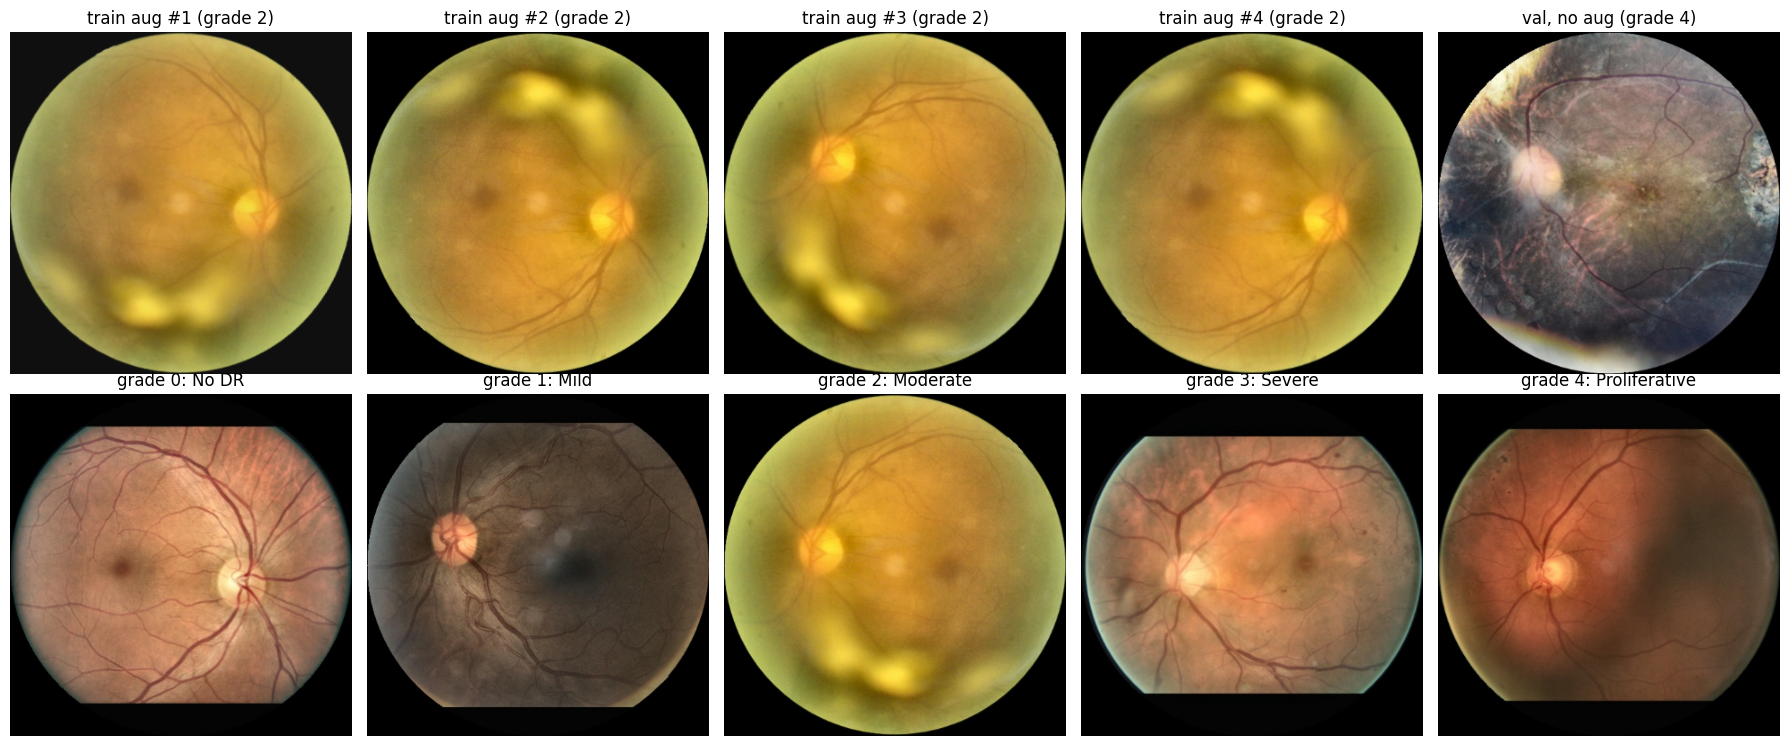

In [ ]:
# Same image 4 times: the train transform changes it every time (flip/rotate/brightness), val does not
ds_tr, ds_va = loaders["train"].dataset, loaders["val"].dataset
fig, ax = plt.subplots(2, 5, figsize=(18, 7.5))
for i in range(4):
    img, lab = ds_tr[0]
    ax[0, i].imshow(denormalize(img)); ax[0, i].set_title(f"train aug #{i + 1} (grade {lab.item()})"); ax[0, i].axis("off")
img, lab = ds_va[0]
ax[0, 4].imshow(denormalize(img)); ax[0, 4].set_title(f"val, no aug (grade {lab.item()})"); ax[0, 4].axis("off")
for i in range(5):   # one training image per grade
    j = sub[(sub.split == "train") & (sub.label == i)].index[0]
    row = sub.loc[[j]]
    from src.data.datasets import RetinaDataset, get_transforms
    im, _ = RetinaDataset(row, get_transforms(IMG_SIZE, train=False))[0]
    ax[1, i].imshow(denormalize(im)); ax[1, i].set_title(f"grade {i}: {CLASS_NAMES[i]}"); ax[1, i].axis("off")
plt.tight_layout(); plt.savefig(OUT / "maheen_dataloader_check.png", dpi=100); plt.show()

## 4. Metrics check
Known example: one small mistake vs one big mistake. Accuracy is the same, QWK must be lower for the big one.

In [ ]:
y_true = [0, 0, 1, 2, 3, 4, 4, 2]
small  = [1, 0, 1, 2, 3, 4, 4, 2]   # grade 0 predicted as 1
big    = [4, 0, 1, 2, 3, 4, 4, 2]   # grade 0 predicted as 4
ms, mb = compute_metrics(y_true, small), compute_metrics(y_true, big)
print(f"small mistake: acc {ms['accuracy']:.3f}, QWK {ms['qwk']:.3f}")
print(f"big mistake:   acc {mb['accuracy']:.3f}, QWK {mb['qwk']:.3f}")
assert ms["accuracy"] == mb["accuracy"] and ms["qwk"] > mb["qwk"]
assert compute_metrics(y_true, y_true)["qwk"] == 1.0
print("Metrics check passed.")

!python -m pytest -q tests/ -p no:cacheprovider

small mistake: acc 0.875, QWK 0.970
big mistake:   acc 0.875, QWK 0.556
Metrics check passed.
.....                                                                    [100%]
5 passed in 1.33s


## 5. Smoke test: train EfficientNet-B4 for 2 epochs
Plain EfficientNet-B4 from `timm`, ImageNet weights, cross-entropy (the baseline settings from `configs/baseline.yaml`).
Checkpoints go to `XRetina_Shared/checkpoints/smoke_maheen_step2/`. Numbers will be low: 2 epochs on 200 images only proves the code runs.

In [ ]:
import timm
RUN_DIR = CKPT / RUN_NAME
shutil.rmtree(RUN_DIR, ignore_errors=True)          # fresh smoke run every time

def make_model():
    return timm.create_model(CFG["model"]["backbone"], pretrained=CFG["model"]["pretrained"],
                             num_classes=CFG["model"]["num_classes"])

smoke_cfg = dict(CFG["train"], epochs=SMOKE_EPOCHS)
trainer = Trainer(make_model(), loaders, smoke_cfg, run_dir=RUN_DIR)
print("device:", trainer.device, "| mixed precision:", trainer.use_amp)
t0 = time.time()
hist = trainer.fit()
print(f"\nSmoke training finished in {time.time() - t0:.0f} s")
display(hist)
assert (RUN_DIR / "last.pt").exists() and (RUN_DIR / "best.pt").exists() and (RUN_DIR / "history.csv").exists()
assert np.isfinite(hist["train_loss"]).all(), "loss is NaN"
print("Checkpoints saved:", sorted(p.name for p in RUN_DIR.iterdir()))

model.safetensors: reconstructing file:   0%|          |  0.00B / 77.9MB            

model.safetensors: downloading bytes:           |  0.00B            

device: cuda | mixed precision: True


epoch 1/2 train:   0%|          | 0/12 [00:00<?, ?it/s]

eval:   0%|          | 0/7 [00:00<?, ?it/s]

epoch  1/2 | train loss 1.8410 | val loss 1.8881 | val acc 0.2100 | val QWK 0.0712 | BEST, saved | 13 s


epoch 2/2 train:   0%|          | 0/12 [00:00<?, ?it/s]

eval:   0%|          | 0/7 [00:00<?, ?it/s]

epoch  2/2 | train loss 1.6390 | val loss 1.7406 | val acc 0.2600 | val QWK 0.1111 | BEST, saved | 6 s

Smoke training finished in 25 s


,epoch,lr,train_loss,val_loss,val_accuracy,val_qwk,val_macro_f1,val_recall_0,val_recall_1,val_recall_2,val_recall_3,val_recall_4,best,seconds
0,1,0.00010,1.84100,1.888054,0.21,0.071174,0.167229,0.15,0.0,0.4,0.45,0.05,True,13.4
1,2,0.00005,1.63905,1.740647,0.26,0.111111,0.240691,0.15,0.2,0.5,0.35,0.10,True,5.9


Checkpoints saved: ['best.pt', 'history.csv', 'last.pt', 'summary.json']


## 6. Resume test
Pretend Colab disconnected: build a brand-new Trainer with 3 epochs. It must load `last.pt` and train **only epoch 3**.

In [ ]:
trainer2 = Trainer(make_model(), loaders, dict(CFG["train"], epochs=SMOKE_EPOCHS + 1), run_dir=RUN_DIR)
hist2 = trainer2.fit()
assert list(hist2["epoch"]) == list(range(1, SMOKE_EPOCHS + 2)), "resume did not continue from the last epoch"
print("Resume test passed: epochs", list(hist2["epoch"]))

Resumed from /content/drive/MyDrive/FYP(Gr2-Fall 2026)/XRetina_Shared/checkpoints/smoke_maheen_step2/last.pt (finished epoch 2, best val qwk = 0.1111)


epoch 3/3 train:   0%|          | 0/12 [00:00<?, ?it/s]

eval:   0%|          | 0/7 [00:00<?, ?it/s]

epoch  3/3 | train loss 1.5305 | val loss 1.6722 | val acc 0.2500 | val QWK 0.1047 | no gain 1/7 | 6 s
Resume test passed: epochs [1, 2, 3]


## 7. Test-set scoring with the best checkpoint
This is exactly how Amna will score the real baseline.

eval:   0%|          | 0/7 [00:00<?, ?it/s]

n = 100 | accuracy = 0.2200 | QWK = 0.0601 | macro F1 = 0.2045
Recall per grade:
  0 No DR          0.200
  1 Mild           0.000
  2 Moderate       0.450
  3 Severe         0.200
  4 Proliferative  0.250


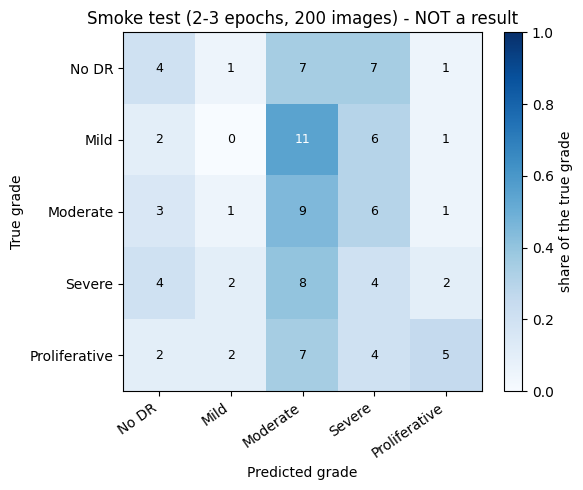

In [ ]:
m_test = trainer2.evaluate(loaders["test"], weights="best")
print(save_metrics(m_test, OUT / "maheen_smoke_test_metrics.json"))
plot_confusion_matrix(m_test["confusion_matrix"], title="Smoke test (2-3 epochs, 200 images) - NOT a result",
                      save_path=OUT / "maheen_smoke_confusion_matrix.png")
plt.show()

## 8. Summary and hand-off

In [ ]:
print("STEP 2 SMOKE TEST PASSED" )
print("- dataloaders: read manifest.csv split column, train-only augmentation, 380 px, batch", BATCH_SIZE)
print("- trainer: AdamW + cosine LR, mixed precision, early stopping on val QWK, best.pt + last.pt every epoch, resume works")
print("- metrics: accuracy, QWK, macro F1, per-grade recall, confusion matrix")
print("Saved to Drive:", RUN_DIR, "and", OUT)
# Clear the big outputs (Edit > Clear all outputs) before pushing, then:
# git_push("Step 2: dataloaders, trainer, metrics + notebook 03 smoke test")

STEP 2 SMOKE TEST PASSED
- dataloaders: read manifest.csv split column, train-only augmentation, 380 px, batch 16
- trainer: AdamW + cosine LR, mixed precision, early stopping on val QWK, best.pt + last.pt every epoch, resume works
- metrics: accuracy, QWK, macro F1, per-grade recall, confusion matrix
Saved to Drive: /content/drive/MyDrive/FYP(Gr2-Fall 2026)/XRetina_Shared/checkpoints/smoke_maheen_step2 and /content/drive/MyDrive/FYP(Gr2-Fall 2026)/XRetina_Shared/outputs


### For Amna (notebook 04): full baseline in 6 lines
```python
man = load_manifest(PROC)                      # after extract_shards(PROC)
loaders = build_dataloaders(man, img_size=380, batch_size=16, num_workers=2)
trainer = Trainer(make_model(), loaders, CFG["train"], run_dir=CKPT / "baseline_b4_ce")
hist = trainer.fit()                           # re-run after a disconnect: it resumes
m = trainer.evaluate(loaders["test"], weights="best")
print(save_metrics(m, OUT / "baseline_b4_ce_test.json"))
```
Per dataset: `load_manifest(PROC, datasets="aptos")` or `datasets="eyepacs"`.
For Aiman (Step 4): pass `loss_fn=FocalLoss(...)` to `Trainer`; nothing else changes.